# Roteiro 6 - Regressão Linear
Este é o roteiro da sexta aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

Esse documento apresenta um modelo linear para previsão usando regressão linear.

Autor: Raoni F. S. Teixeira - raoni.teixeira@ufmt.br
___________________

# 1. Previsão da venda de sorvetes


O primeiro experimento utiliza a base de dados [Temperature and Ice Cream Sales](https://www.kaggle.com/datasets/raphaelmanayon/temperature-and-ice-cream-sales/data), disponível no kaggle.

Como veremos, há uma correlação positiva entre a temperatura e as vendas de sorvete: quanto mais alta a temperatura, maior o volume de vendas, já que o calor estimula o consumo.



Antes de qualquer coisa, carregue os pacotes para leitura e visualização de dados.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

## Obtendo os dados

In [ ]:
# Baixe os dados
!gdown 1ChL4xxy_dEh-XLXhUOrPAfNVXOFqmfZn

Downloading...
From: https://drive.google.com/uc?id=1ChL4xxy_dEh-XLXhUOrPAfNVXOFqmfZn
To: /content/icecream.csv
100% 3.68k/3.68k [00:00<00:00, 11.9MB/s]


## Lendo o arquivo

Os dados são um conjunto de $364$ amostras com  a temperatura e lucros de uma soverteria medidos diariamente. A temperatura é medida em Fahrenheit.

In [ ]:
df = pd.read_csv('icecream.csv', sep=',', header='infer')
df = df.rename(columns={'Ice Cream Profits': 'Profits'})
#df.columns = ['Temperature', 'Ice Cream Profits']
print(df)

     Temperature  Profits
0             39    13.17
1             40    11.88
2             41    18.82
3             42    18.65
4             43    17.02
..           ...      ...
360           99    85.13
361           99    87.08
362           99    89.29
363          101    81.91
364          101    85.02

[365 rows x 2 columns]


## Visualizando os dados

Os dados indicam uma relação entre as duas variáveis. Essa relação faz sentido na prática, já que o calor tende a aumentar o consumo de produtos gelados.

A correlação entre as variáveis é de **0,988**, o que sugere que a temperatura pode ser usada em um modelo de aprendizado de máquina para prever o lucro da sorveteria. Com base nisso, o dono poderia utilizar o modelo para planejar o movimento da loja, a quantidade de funcionários necessários e a produção de sorvetes.

**Importante**:

Testes de correlação são úteis para identificar relações entre variáveis. No entanto, observar que duas variáveis se movem juntas não significa que uma cause a outra. Por isso, é comum dizer que "correlação não implica causalidade".

### Matriz de Correlação

In [ ]:
print(df.corr())

             Temperature   Profits
Temperature     1.000000  0.988446
Profits         0.988446  1.000000


### Gráfico

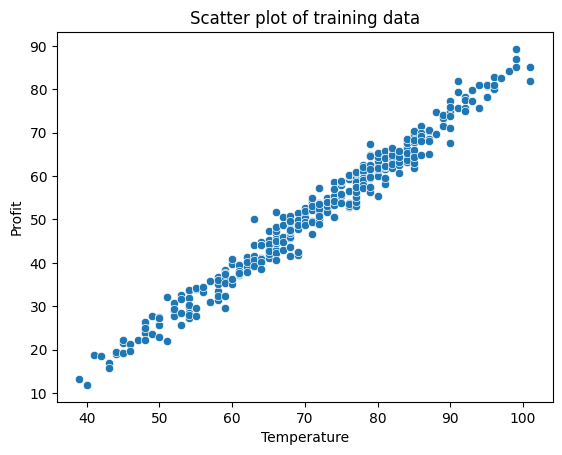

In [ ]:
ax = sns.scatterplot(x='Temperature', y='Profits', data=df)
ax.set(xlabel='Temperature', ylabel='Profit', title='Scatter plot of training data');

## Descida do Gradiente

Como encontrar os parâmetros de **regressão linear** para o conjunto de dados usando gradiente descendente?


### 1. Preparação dos dados

Para facilitar a otmização, os dados de entrada `X` são  normalizados para ter média 0 e desvio padrão 1.  Além disso, uma coluna de uns é adicionada para o termo de bias.


In [ ]:
m = df.shape[0]
X = df.iloc[:,0].values.reshape(-1,1)

y = np.array(df.Profits.values).reshape(-1,1)

# Salva a média e o desvio padrão de X antes da normalização
mu = np.mean(X, axis=0)
sigma = np.std(X, axis=0)

# Normaliza X
X_normalized = (X - mu) / sigma

# Adiciona uma coluna de uns para o termo de bias
X_normalized = np.hstack((np.ones((m, 1)), X_normalized))

theta = np.zeros(shape=(X_normalized.shape[1],1))

### 2. Função de custo (erro de previsão do modelo)

O objetivo da regressão linear é minimizar a função de custo $J(\theta)$, que mede o erro entre as previsões do modelo $ h_\theta(x)$ e os valores reais $y $. A função de custo é definida como:

$
J(\theta) = \frac{1}{2m} \sum_{i=1}^m \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2
$

Onde:
- $ m $ é o número de exemplos no conjunto de dados.
- $ x^{(i)}$ e $ y^{(i)} $ são o $ i$-ésimo exemplo e seu valor alvo, respectivamente.


In [ ]:
def compute_cost_one_variable(X, y, theta):
    m = len(y)
    h = X.dot(theta)
    cost = (1/(2*m)) * np.sum((h - y)**2)
    return cost

In [ ]:
J = compute_cost_one_variable(X_normalized, y, theta)
print('Com theta = [0 ; 0]\nCusto =', J)

Com theta = [0 ; 0]
Custo = 1484.8673432876712


### 3. Otimização via descida do Gradiente

A regressão linear é um método para modelar a relação entre uma variável dependente $y$ e uma ou mais variáveis independentes $X$. A hipótese da regressão linear é dada por:

$
h_\theta(x) = \theta^T x = \theta_0 + \theta_1 x_1
$

Onde:
- $ \theta = [\theta_0, \theta_1] $ são os parâmetros do modelo.
- $ x = [1, x_1] $ é o vetor de features (com $ x_0 = 1 $ para o termo de bias).


Para minimizar $ J(\theta) $, usamos o algoritmo de **gradiente descendente em lote**. Em cada iteração, os parâmetros $ \theta $ são atualizados da seguinte forma:

$
\theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^m \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}
$

Onde:
- $ \alpha $ é a taxa de aprendizado (um hiperparâmetro que controla o tamanho do passo).
- $ x_j^{(i)} $ é o valor da $ j $-ésima feature no $ i $-ésimo exemplo.

Essa atualização é aplicada simultaneamente para todos os parâmetros $\theta_j $. A cada passo, $ \theta_j $ se aproxima dos valores ótimos que minimizam $ J(\theta) $.



In [ ]:
def gradient_descent(X, y, theta, alpha, num_iters):
    m = y.shape[0]
    J_history = np.zeros(shape=(num_iters, 1))

    for i in range(0, num_iters):
        h = X.dot(theta)
        diff_hy = h - y

        delta = (1/m) * (X.T.dot(diff_hy))
        theta = theta - alpha * delta
        J_history[i] = compute_cost_one_variable(X, y, theta)

        if i > 0 and J_history[i] > J_history[i-1]:
            print('Divergencia ', i)
            break

    return theta, J_history

In [ ]:
iterations = 1000
alpha = 0.01
theta, J_h = gradient_descent(X_normalized, y, theta, alpha, iterations)
print('Theta encontrado pela descida do gradiente:\n', theta)
#print(J_h)

Theta encontrado pela descida do gradiente:
 [[52.10136706]
 [15.78191667]]


### 4. Visualização do resultado

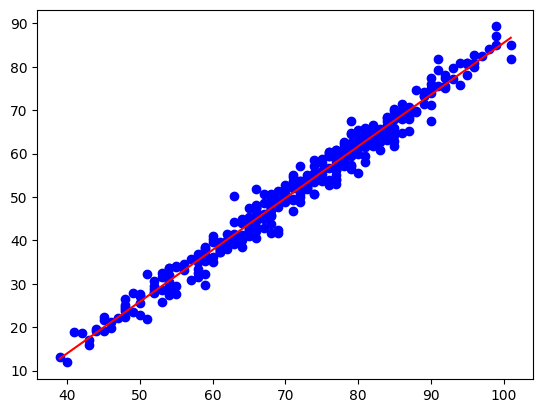

In [ ]:
theta_original = np.zeros_like(theta)
theta_original[0] = theta[0] - (theta[1] * mu / sigma)  # Ajusta o termo de bias
theta_original[1] = theta[1] / sigma
plt.scatter(X, y, color="blue", label="Dados originais")  # Plota os dados originais

# Gera pontos para a linha de regressão
X_plot = np.linspace(np.min(X), np.max(X), 100).reshape(-1, 1)
y_plot = theta_original[0] + theta_original[1] * X_plot  # Calcula y usando theta_original

# Plota a linha de regressão
plt.plot(X_plot, y_plot, color="red", label="Reta de regressão")


### 4. Visualizando a função $J(\theta)$


A função de custo J(\theta) tem formato de tigela e tem apenas um mínimo global. Este mínimo é o ponto ótimo para $\theta_0$ e $\theta_1$, e a cada passo a descida do gradiente se aproxima mais deste ponto.

O gráfico abaixo mostra que a cada iteração o custo diminui.

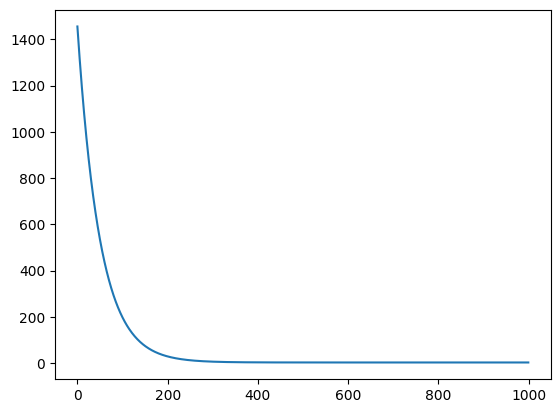

In [ ]:
plt.plot(J_h[:])

As curvas de nível a seguir mostram a topologia da função $J$ em formato de tigela e que a descida do gradiente encontra o mínimo dessa função.

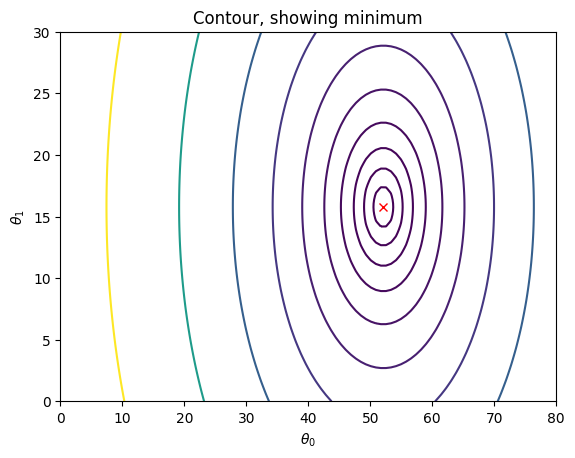

In [ ]:
theta0_vals = np.linspace(0, 80, 100)
theta1_vals = np.linspace(0, 30, 100)
J_vals = np.zeros(shape=(len(theta0_vals), len(theta1_vals)))

for i in range(0, len(theta0_vals)):
    for j in range(0, len(theta1_vals)):
        J_vals[i,j] = compute_cost_one_variable(X_normalized, y, [[theta0_vals[i]], [theta1_vals[j]]])

ax = plt.contour(theta0_vals, theta1_vals, np.transpose(J_vals), levels=np.logspace(-2,3,20))
plt.plot(theta[0,0], theta[1,0], marker='x', color='r');
plt.xlabel(r'$\theta_0$');
plt.ylabel(r'$\theta_1$');
plt.title('Contour, showing minimum');

## Solução usando pacote `sklearn`

Coeficiente angular (inclinação): 1.1920
Coeficiente linear (intercepto): -33.6982


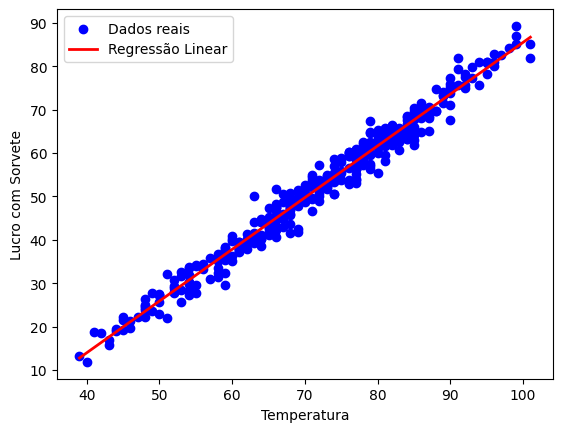

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Carregar os dados
#data = np.loadtxt("icecream.csv", delimiter=",")  # Substitua pelo nome do seu arquivo se necessário
data = np.loadtxt("icecream.csv", delimiter=",", skiprows=1)
X = data[:, 0].reshape(-1, 1)  # Temperatura
y = data[:, 1]  # Lucros com sorvete

# Treinar o modelo de regressão linear
model = LinearRegression()
model.fit(X, y)

# Fazer previsões
y_pred = model.predict(X)

# Coeficientes do modelo
print(f"Coeficiente angular (inclinação): {model.coef_[0]:.4f}")
print(f"Coeficiente linear (intercepto): {model.intercept_:.4f}")

# Visualizar os dados e a reta de regressão
plt.scatter(X, y, color="blue", label="Dados reais")
plt.plot(X, y_pred, color="red", linewidth=2, label="Regressão Linear")
plt.xlabel("Temperatura")
plt.ylabel("Lucro com Sorvete")
plt.legend()
plt.show()

# 2. Prevendo o preço de casas

Nesta parte, você implementará a regressão linear com múltiplas variáveis ​​para prever os preços das casas. Suponha que você esteja vendendo sua casa e queira saber qual seria um bom preço de mercado. Uma maneira de fazer isso é primeiro coletar informações sobre casas vendidas recentemente e fazer um modelo de preços de moradias. O arquivo `ex1data2.txt` contém um conjunto de treinamento de preços de moradias em Portland, Oregon. A primeira coluna é o tamanho da casa (em metros quadrados), a segunda coluna é o número de quartos e a terceira coluna é o preço da casa.

Carregue os pacotes

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

## Obtendo os dados

In [ ]:
!gdown 1KCV4ocOLEsy6SvJRAfAJ2TB6StIKvOGY

Downloading...
From: https://drive.google.com/uc?id=1KCV4ocOLEsy6SvJRAfAJ2TB6StIKvOGY
To: /content/ex1data2.txt
100% 657/657 [00:00<00:00, 3.02MB/s]


In [ ]:
df2 = pd.read_csv('ex1data2.txt', sep=',', header=None)
df2.columns = ['house_size', 'bedrooms', 'house_price']
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
house_size,47.0,2000.680851,794.702354,852.0,1432.0,1888.0,2269.0,4478.0
bedrooms,47.0,3.170213,0.760982,1.0,3.0,3.0,4.0,5.0
house_price,47.0,340412.659574,125039.899586,169900.0,249900.0,299900.0,384450.0,699900.0


## Descida do Gradiente

A única diferença do problema de regressão univariada é que agora há mais uma característica na matriz `X`. A função de $h$ e a regra de atualização de descida de gradiente em lote permanecem inalteradas.

No caso multivariado, a função de custo também pode ser escrita na seguinte forma vetorizada:

$J(\theta) = \frac{1}{2m}(X\theta-y)^T(X\theta-y)$

In [ ]:
def feature_normalize(X, mean=np.zeros(1), std=np.zeros(1)):
    X = np.array(X)
    if len(mean.shape) == 1 or len(std.shape) == 1:
        mean = np.mean(X, axis=0)
        std = np.std(X, axis=0, ddof=1)

    X = (X - mean)/std
    return X, mean, std

In [ ]:
X_norm, mu, sigma = feature_normalize(df2[['house_size', 'bedrooms']])


In [ ]:
def compute_cost(X, y, theta):
    m = y.shape[0]
    h = X.dot(theta)
    J = (1/(2*m)) * ((h-y).T.dot(h-y))
    return J

In [ ]:
def gradient_descent(X, y, theta, alpha, num_iters):
    m = y.shape[0]
    J_history = np.zeros(shape=(num_iters, 1))

    for i in range(0, num_iters):
        h = X.dot(theta)
        diff_hy = h - y

        delta = (1/m) * (diff_hy.T.dot(X))
        theta = theta - (alpha * delta.T)
        J_history[i] = compute_cost(X, y, theta)

    return theta, J_history

## Selecionando a taxa de aprendizado

Dicas:
* Faça um gráfico com o número de iterações no eixo x. Agora, plote a função de custo, $J(\theta)$ sobre o número de iterações da descida do gradiente. Se $J(\theta)$ aumentar, então você provavelmente precisará diminuir $\\alpha$.
* Declare convergene se $J(\theta)$ diminuir em menos que E em uma iteração, onde E é algum valor pequeno como $10^{−3}$.

In [ ]:
m = df2.shape[0]
X = np.hstack((np.ones((m,1)),X_norm))
y = np.array(df2.house_price.values).reshape(-1,1)
theta = np.zeros(shape=(X.shape[1],1))


In [ ]:
alpha = [0.3, 0.1, 0.03, 0.01]
colors = ['b','r','g','c']
num_iters = 50

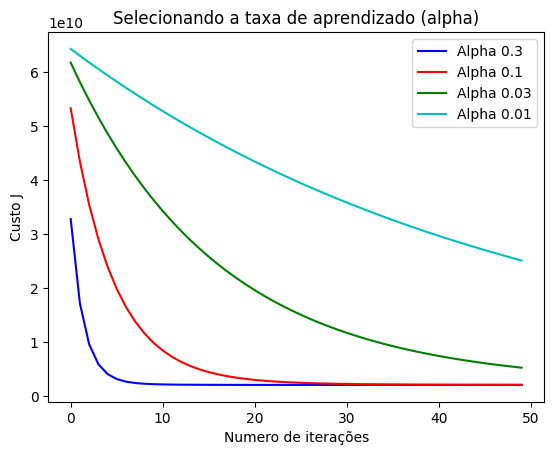

In [ ]:
for i in range(0, len(alpha)):
    theta = np.zeros(shape=(X.shape[1],1))
    theta, J_history = gradient_descent(X, y, theta, alpha[i], num_iters)
    plt.plot(range(len(J_history)), J_history, colors[i], label='Alpha {}'.format(alpha[i]))
plt.xlabel('Numero de iterações');
plt.ylabel('Custo J');
plt.title('Selecionando a taxa de aprendizado (alpha)');
plt.legend()
plt.show()

In [ ]:
iterations = 250
alpha = 0.1
theta, _ = gradient_descent(X, y, theta, alpha, iterations)

print('Theta encontrado pela descida do gradiente:')
print(theta)

Theta encontrado pela descida do gradiente:
[[340412.65957372]
 [110630.26530813]
 [ -6648.6893001 ]]


In [ ]:
sqft = (1650 - mu[0])/sigma[0]
bedrooms = (3 - mu[1])/sigma[1]
y_pred = theta[0] + theta[1]*sqft + theta[2]*bedrooms
f'Preço da casa com 1650 metros quadrados e 3 quartos: {y_pred[0]}$'

'Preço da casa com 1650 metros quadrados e 3 quartos: 293081.63514221634$'

## Solução usando pacote `sklearn`




In [ ]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_norm, y)

LinearRegression()

In [ ]:
lin_reg.intercept_, lin_reg.coef_


(array([340412.65957447]), array([[110631.05027885,  -6649.47427082]]))